# 01 — Measurements by Water Type and Decade

Produces manuscript **Figure 1**: restored table rows / recorded values by water category and decade, California only (core water types, dated tables incl. period-of-record / construction-year dates, any location quality). Also writes the all-locations version for the supplement.

Requires `data/analysis/table_level_metadata_published.csv` (the LLM-processed publication subset, produced by `filter_published_tables.py`). This is one row per digitized table — using it avoids the page-level double-counting that inflated earlier versions of this figure.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
import sys
sys.path.insert(0, str(Path('.')))   # so water_palette imports cleanly
from water_palette import CATEGORY_ORDER, get_color_for
from paper_filters import drop_tribal
from date_parsing import FALLBACK_STATUSES

root         = Path('../..')
table_path   = root / 'data/analysis/table_level_metadata_published.csv'
figures_path = root / 'manuscript/figures'
figures_path.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(table_path)
print(f'Loaded {len(df):,} table rows')
# tribal pages are withheld from paper figures and statistics (paper_filters.py)
df = drop_tribal(df, id_col='doc_id')
# decades come from table-level dates (date_parsing.apply_table_dates); undated tables drop out below
print(df['date_status'].value_counts().to_string())

C:\Users\aeliz\AppData\Local\Temp\ipykernel_25152\782098933.py:17: DtypeWarning: Columns (0: review_action) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(table_path)


Loaded 100,829 table rows
tribal pages excluded: 3,102 of 100,829 rows
date_status
table_caption        51627
table_date_column    23567
table_text            8885
page_text             7488
undated               4820
period_of_record       835
construction_year      505


## Filter and aggregate

Keep only primary water categories (exclude 'Not Water Related' and 'Other'). One row per table; group by decade × water type and sum estimated measurements (`number_rows`).

In [2]:
# Figure 1 (Annette, 2026-11-14; was Fig 7): California only; core water types only; dated tables only,
# where "dated" includes the loose (fallback) dates -- period of record and construction year.
# Not restricted by location quality (unlocated California tables are included).
# Base = catalog: published LLM tables, rebuilt locations + table-level dates, tribal pages removed.
from paper_filters import data_page_mask

cat = pd.read_csv(root / 'data/catalog/restored_tables_catalog.csv', low_memory=False)
n0 = len(cat)
cat = cat[data_page_mask(cat)]          # drop index / report-list / narrative pages
print(f'non-data pages removed: {n0 - len(cat):,} tables')

pst = pd.read_csv(root / 'data/analysis/location_validation/page_states.csv').rename(columns={'id': 'doc_id'})
cat = cat.merge(pst[['doc_id', 'page_number', 'page_state_class']], on=['doc_id', 'page_number'], how='left')

# California membership:
#   point (precise/approximate) -> its state; points with no state are outside the US (mostly Baja, Tijuana R.)
#   basin point (DWR Bulletin 118)  -> California
#   unlocated / conflicting coords  -> California unless the page names only other states
pc = cat['precision_class']
has_point = pc.isin(['precise', 'approximate'])
cat['ca_group'] = np.select(
    [has_point & (cat['state'] == 'California'),
     has_point,
     pc.eq('basin'),
     cat['page_state_class'].eq('out_of_state')],
    ['ca_located', 'outside_ca', 'ca_located', 'outside_ca'],
    default='ca_unlocated')

PLOT_ORDER = list(CATEGORY_ORDER)        # the 7 core water types (no Other / Not Water Related)
COLORS = {c: get_color_for(c) for c in CATEGORY_ORDER}
core = cat['water_type'].isin(PLOT_ORDER)
dated = cat['year_start'].notna()        # measurement dates + period-of-record / construction-year dates
print('left out, not a core water type:', cat.loc[~core, ['n_measurements', 'n_values']].sum().to_dict())
print('left out, undated (core types):', cat.loc[core & ~dated, ['n_measurements', 'n_values']].sum().to_dict())
print('loose dates included (core types):',
      cat.loc[core & cat['date_status'].isin(FALLBACK_STATUSES), ['n_measurements', 'n_values']].sum().to_dict())
cat = cat[core & dated].copy()

dec = (cat['year_start'] // 10 * 10).astype(int)
cat['bin'] = np.where(dec < 1850, 'Before\n1850', dec.astype(str) + 's')
# Records run through 1979 (the 1980 decade only holds records starting in 1980 itself) -> left out
late = cat['bin'].eq('1980s')
print('left out, 1980 starts:', cat.loc[late, ['n_measurements', 'n_values']].sum().to_dict())
cat = cat[~late]
BIN_ORDER = ['Before\n1850'] + [f'{d}s' for d in range(1850, 1980, 10)]
# Decade = decade of each table's START year (year_start); all of a table's measurements are
# counted there (Annette, 2026-11-14; explained in the caption). ~15% of measurements are in
# tables that run into a later decade. A spread-over-years version was compared and not used.

def build(df, measure):
    pv = df.pivot_table(index='bin', columns='water_type', values=measure, aggfunc='sum', fill_value=0)
    pv = pv.reindex([b for b in BIN_ORDER if b in pv.index]).reindex(columns=[c for c in PLOT_ORDER if c in pv.columns])
    return pv.fillna(0)

ca = cat[cat['ca_group'] != 'outside_ca']
print('\nCalifornia tables by location group:')
print(ca.groupby('ca_group')[['n_measurements', 'n_values']].agg(['count', 'sum']).to_string(), '\n')
pivots = {}
for scope, d in [('ca', ca), ('all', cat)]:
    for key, measure in [('rows', 'n_measurements'), ('values', 'n_values')]:
        pv = build(d, measure)
        pivots[(scope, key)] = pv
        print(f'[{scope} / {measure}] total {pv.values.sum():,.0f}')
print()
print(pivots[('ca', 'values')].astype(int).to_string())
print()
print(pivots[('ca', 'rows')].astype(int).to_string())



non-data pages removed: 628 tables
left out, not a core water type: {'n_measurements': 21561.0, 'n_values': 108163.0}
left out, undated (core types): {'n_measurements': 88862.0, 'n_values': 412876.0}
loose dates included (core types): {'n_measurements': 21477.0, 'n_values': 118900.0}
left out, 1980 starts: {'n_measurements': 35.0, 'n_values': 194.0}



California tables by location group:
             n_measurements            n_values          
                      count        sum    count       sum
ca_group                                                 
ca_located            75864  1910603.0    75895  14662985
ca_unlocated           9767   226222.0     9855   1514220 

[ca / n_measurements] total 2,136,825
[ca / n_values] total 16,177,205
[all / n_measurements] total 2,297,244
[all / n_values] total 17,229,903

water_type    Stream Discharge  Groundwater  Precipitation  Irrigation  Reservoir  Springs  Water Quality
bin                                                                                                      
Before\n1850                 0            0           1285           0          0        0              0
1850s                      556            0            840           0         48       77              0
1860s                     1248          825           2192           0         95       25           

## Figure 1 — Measurements by water type × decade

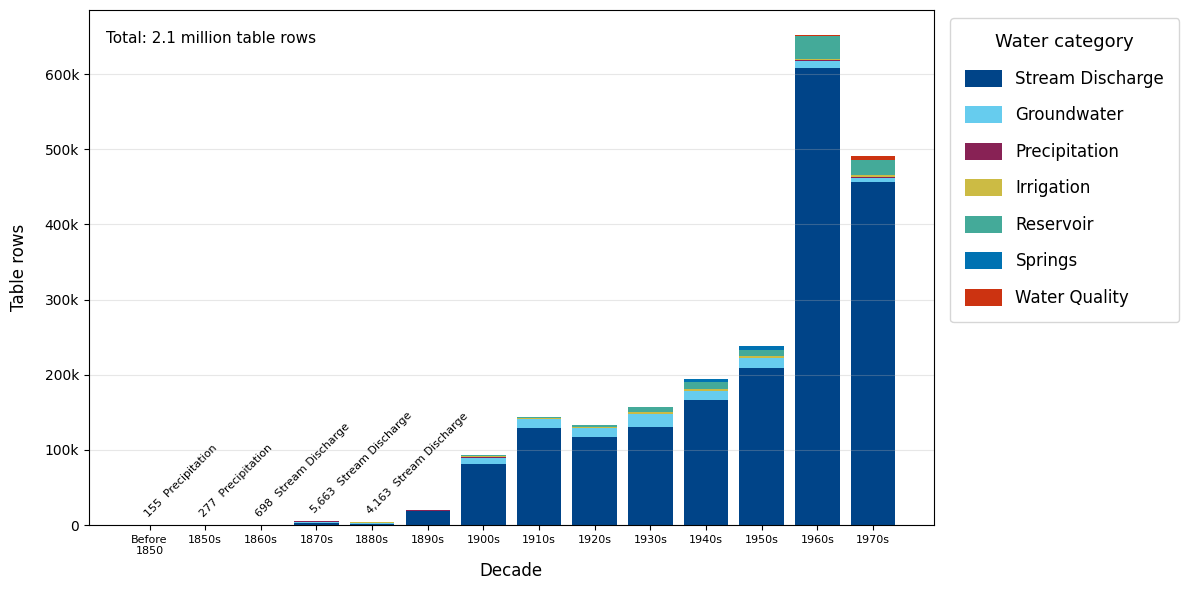

Saved fig1_measurements_by_type_decade_rows.png (total 2,136,825)


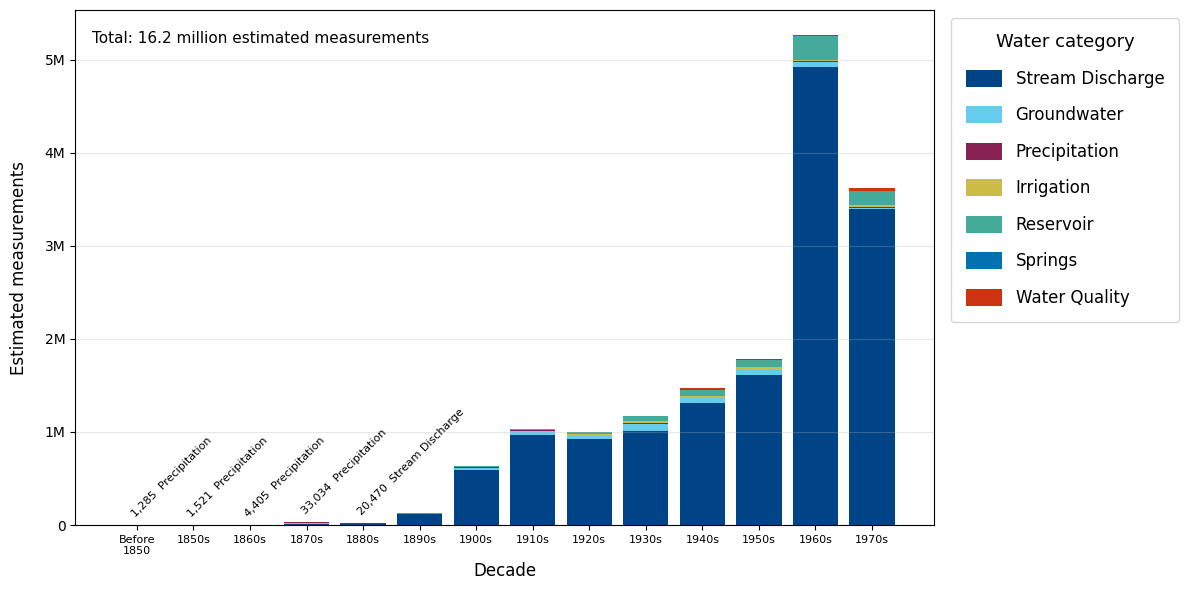

Saved fig1_measurements_by_type_decade_values.png (total 16,177,205)


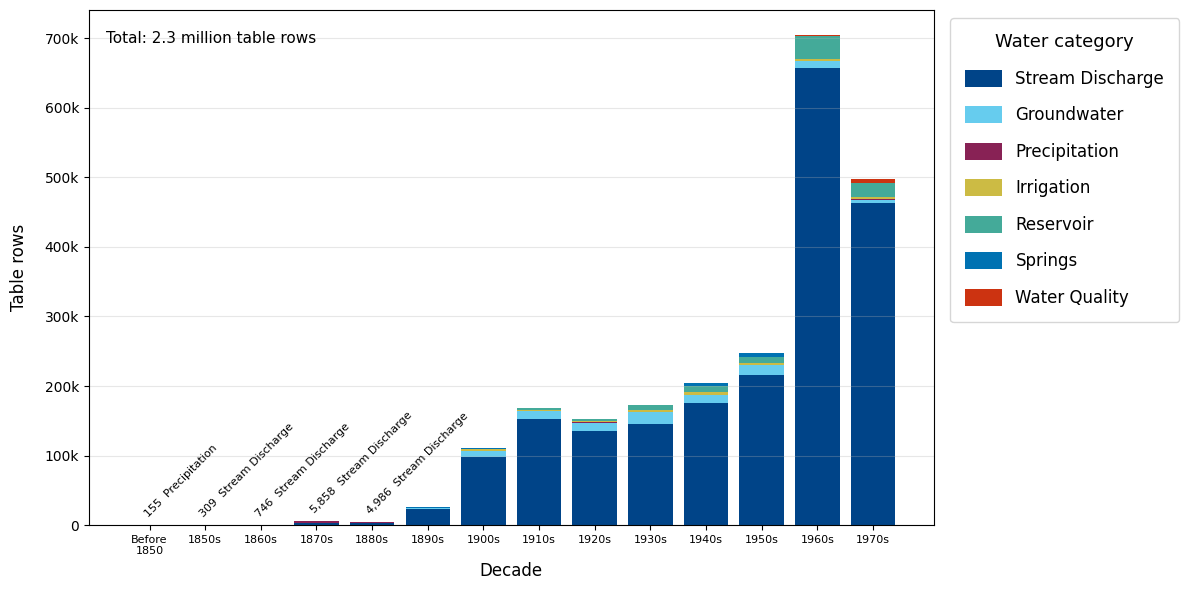

Saved supp_all_locations_measurements_by_type_decade_rows.png (total 2,297,244)


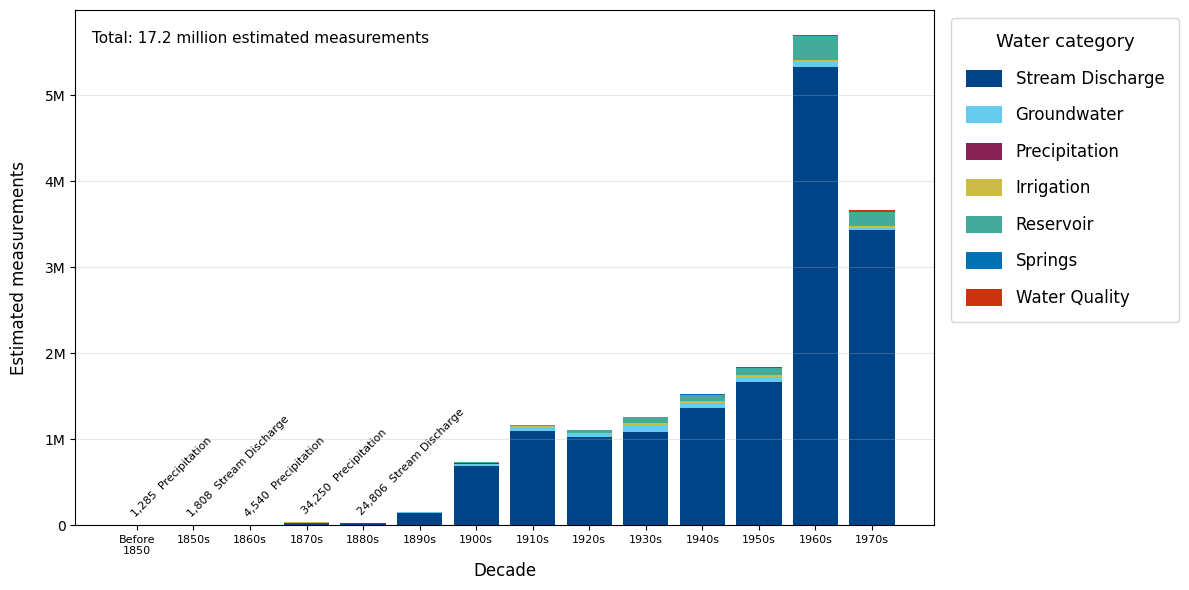

Saved supp_all_locations_measurements_by_type_decade_values.png (total 17,229,903)


In [3]:
# Figure 1 styling (Annette, 2026-11-14): no title; y = "Estimated measurements";
# decades too small to see (before 1850 - 1880s) labeled with total + dominant water category.
YLAB = {'rows': 'Table rows', 'values': 'Estimated measurements'}
TOTAL = {'rows': 'table rows', 'values': 'estimated measurements'}   # 'unique' dropped (Annette, 2026-11-15)
SMALL_BINS = ['Before\n1850', '1850s', '1860s', '1870s', '1880s']

def fmt(v, _=None):
    return f'{v/1e6:.0f}M' if v >= 1e6 else (f'{v/1e3:.0f}k' if v else '0')

for (scope, key), pivot in pivots.items():
    fig, ax = plt.subplots(figsize=(12, 6))
    labels = list(pivot.index)
    x = np.arange(len(labels), dtype=float)
    bottom = np.zeros(len(labels))
    for wtype in pivot.columns:
        v = pivot[wtype].values
        ax.bar(x, v, 0.8, bottom=bottom, color=COLORS[wtype], label=wtype)
        bottom = bottom + v

    totals = pivot.sum(axis=1).values
    pad = 0.012 * totals.max()
    for i, b in enumerate(labels):
        if b in SMALL_BINS:
            top = pivot.loc[b].idxmax()
            # diagonal labels (Annette, 2026-11-15), anchored at the bar top
            ax.text(x[i], totals[i] + pad, f'{int(totals[i]):,}  {top}', ha='left', va='bottom',
                    fontsize=8, rotation=45, rotation_mode='anchor')

    tot = totals.sum()
    ax.text(0.02, 0.96, f'Total: {tot/1e6:.1f} million {TOTAL[key]}', transform=ax.transAxes,
            va='top', fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0, fontsize=8)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt))
    ax.set_xlabel('Decade', fontsize=12)
    ax.set_ylabel(YLAB[key], fontsize=12, labelpad=12)   # space between label and axis (2026-11-15)
    # bigger, more spaced legend (Annette, 2026-11-15)
    ax.legend(title='Water category', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=12,
              title_fontsize=13, labelspacing=1.1, handlelength=2.2, handleheight=1.2, borderpad=0.9)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    prefix = 'fig1' if scope == 'ca' else 'supp_all_locations'
    out = figures_path / f'{prefix}_measurements_by_type_decade_{key}.png'
    plt.savefig(out, dpi=300, bbox_inches='tight')
    plt.show()
    print('Saved', out.name, f'(total {tot:,.0f})')
